In [1]:
# Step 2: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

print("CareerLens project setup completed!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


CareerLens project setup completed!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [2]:

# Step 4: Load the dataset

dataset_url = "https://huggingface.co/datasets/Uzaib52/indian-tech-career-intelligence-2026/resolve/main/indian_tech_career_intelligence_2026.csv"

df = pd.read_csv(dataset_url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Dataset shape: (100000, 33)

First 5 rows:


,job_title,job_category,company_name,company_size,industry,company_type,location_city,location_state,location_country,work_mode,...,application_deadline,source_platform,applicant_count,job_benefits,technical_domain,interview_difficulty,probation_period,shift_type,is_active,career_growth_index
0,Machine Learning Engineer,AI / ML Engineering,TCS,"10,000+ employees",Information Technology,Top MNC,Delhi NCR,Delhi,India,On-site,...,16-03-2026,LinkedIn,193,"Stock Options (ESOPs), Free Meals, Remote Firs...",Core Applied Machine Learning,Medium,3 Months,Flexible Shift,False,85%
1,Full Stack Developer,Web Development,Ola Electric,"1,000-5,000 employees",Information Technology,Tech Startup,Gurgaon,Haryana,India,Remote,...,01-03-2026,AmbitionBox,465,"Paid Time Off, Medical Cover, Annual Bonus",Frontend & Backend Engineering,Easy,3 Months,Flexible Shift,True,65%
2,Web Development Intern,Web Development,Cognizant,"10,000+ employees",Information Technology,Top MNC,Pune,Maharashtra,India,Remote,...,07-02-2026,Glassdoor,77,"Paid Time Off, Medical Cover, Annual Bonus",Frontend & Backend Engineering,Medium,6 Months,Flexible Shift,True,70%
3,DevOps Intern,DevOps Core,Infosys,"10,000+ employees",Information Technology,Top MNC,Gurgaon,Haryana,India,Remote,...,14-06-2026,AmbitionBox,387,"Health Insurance, Flexible Hours, Work from Ho...",Cloud & Infrastructure Systems,Medium,3 Months,Day Shift,True,84%
4,Cybersecurity Analyst,Cybersecurity,Swiggy,"1,000-5,000 employees",Information Technology,Tech Startup,Bangalore,Karnataka,India,On-site,...,22-06-2026,AmbitionBox,27,"Health Insurance, Flexible Hours, Work from Ho...",Network & Information Security,Hard,NaN,Day Shift,True,82%


In [3]:
# Step 5: Explore the dataset

print("1. Dataset size:")
print(df.shape)

print("\n2. Column names:")
print(df.columns.tolist())

print("\n3. First 5 rows:")
display(df.head())

print("\n4. Dataset information:")
df.info()

print("\n5. Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\n6. Duplicate rows:")
print(df.duplicated().sum())

1. Dataset size:
(100000, 33)

2. Column names:
['job_title', 'job_category', 'company_name', 'company_size', 'industry', 'company_type', 'location_city', 'location_state', 'location_country', 'work_mode', 'salary_minimum', 'salary_maximum', 'salary_currency', 'stipend_amount', 'experience_level', 'experience_required', 'education_required', 'employment_type', 'contract_type', 'skills_extracted', 'skill_count', 'job_description', 'posted_date', 'application_deadline', 'source_platform', 'applicant_count', 'job_benefits', 'technical_domain', 'interview_difficulty', 'probation_period', 'shift_type', 'is_active', 'career_growth_index']

3. First 5 rows:


,job_title,job_category,company_name,company_size,industry,company_type,location_city,location_state,location_country,work_mode,...,application_deadline,source_platform,applicant_count,job_benefits,technical_domain,interview_difficulty,probation_period,shift_type,is_active,career_growth_index
0,Machine Learning Engineer,AI / ML Engineering,TCS,"10,000+ employees",Information Technology,Top MNC,Delhi NCR,Delhi,India,On-site,...,16-03-2026,LinkedIn,193,"Stock Options (ESOPs), Free Meals, Remote Firs...",Core Applied Machine Learning,Medium,3 Months,Flexible Shift,False,85%
1,Full Stack Developer,Web Development,Ola Electric,"1,000-5,000 employees",Information Technology,Tech Startup,Gurgaon,Haryana,India,Remote,...,01-03-2026,AmbitionBox,465,"Paid Time Off, Medical Cover, Annual Bonus",Frontend & Backend Engineering,Easy,3 Months,Flexible Shift,True,65%
2,Web Development Intern,Web Development,Cognizant,"10,000+ employees",Information Technology,Top MNC,Pune,Maharashtra,India,Remote,...,07-02-2026,Glassdoor,77,"Paid Time Off, Medical Cover, Annual Bonus",Frontend & Backend Engineering,Medium,6 Months,Flexible Shift,True,70%
3,DevOps Intern,DevOps Core,Infosys,"10,000+ employees",Information Technology,Top MNC,Gurgaon,Haryana,India,Remote,...,14-06-2026,AmbitionBox,387,"Health Insurance, Flexible Hours, Work from Ho...",Cloud & Infrastructure Systems,Medium,3 Months,Day Shift,True,84%
4,Cybersecurity Analyst,Cybersecurity,Swiggy,"1,000-5,000 employees",Information Technology,Tech Startup,Bangalore,Karnataka,India,On-site,...,22-06-2026,AmbitionBox,27,"Health Insurance, Flexible Hours, Work from Ho...",Network & Information Security,Hard,NaN,Day Shift,True,82%



4. Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   job_title             100000 non-null  object
 1   job_category          100000 non-null  object
 2   company_name          100000 non-null  object
 3   company_size          100000 non-null  object
 4   industry              100000 non-null  object
 5   company_type          100000 non-null  object
 6   location_city         100000 non-null  object
 7   location_state        100000 non-null  object
 8   location_country      100000 non-null  object
 9   work_mode             100000 non-null  object
 10  salary_minimum        100000 non-null  int64 
 11  salary_maximum        100000 non-null  int64 
 12  salary_currency       100000 non-null  object
 13  stipend_amount        100000 non-null  int64 
 14  experience_level      100000 non-null  objec

,0
probation_period,33499
job_title,0
job_category,0
company_size,0
company_name,0
company_type,0
location_city,0
location_state,0
industry,0
work_mode,0



6. Duplicate rows:
0


In [4]:
# Step 6: Clean the dataset

# Save the original number of rows
original_rows = len(df)

# Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Remove duplicate rows
df = df.drop_duplicates()

# Display the cleaning results
print("DATA CLEANING REPORT")
print("-" * 30)

print("Rows before cleaning:", original_rows)
print("Rows after removing duplicates:", len(df))
print("Duplicate rows removed:", original_rows - len(df))

print("\nMissing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nUpdated dataset shape:", df.shape)

print("\nUpdated column names:")
print(df.columns.tolist())

DATA CLEANING REPORT
------------------------------
Rows before cleaning: 100000
Rows after removing duplicates: 100000
Duplicate rows removed: 0

Missing values in each column:


,0
probation_period,33499
job_title,0
job_category,0
company_size,0
company_name,0
company_type,0
location_city,0
location_state,0
industry,0
work_mode,0



Updated dataset shape: (100000, 33)

Updated column names:
['job_title', 'job_category', 'company_name', 'company_size', 'industry', 'company_type', 'location_city', 'location_state', 'location_country', 'work_mode', 'salary_minimum', 'salary_maximum', 'salary_currency', 'stipend_amount', 'experience_level', 'experience_required', 'education_required', 'employment_type', 'contract_type', 'skills_extracted', 'skill_count', 'job_description', 'posted_date', 'application_deadline', 'source_platform', 'applicant_count', 'job_benefits', 'technical_domain', 'interview_difficulty', 'probation_period', 'shift_type', 'is_active', 'career_growth_index']


In [5]:
# Step 7.1: Check available columns

print("Available columns in CareerLens:")
for column in df.columns:
    print("-", column)

Available columns in CareerLens:
- job_title
- job_category
- company_name
- company_size
- industry
- company_type
- location_city
- location_state
- location_country
- work_mode
- salary_minimum
- salary_maximum
- salary_currency
- stipend_amount
- experience_level
- experience_required
- education_required
- employment_type
- contract_type
- skills_extracted
- skill_count
- job_description
- posted_date
- application_deadline
- source_platform
- applicant_count
- job_benefits
- technical_domain
- interview_difficulty
- probation_period
- shift_type
- is_active
- career_growth_index


In [6]:
# Check the type of data in each column

print("Dataset information:")
df.info()

print("\nSample records:")
display(df.head(5))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   job_title             100000 non-null  object
 1   job_category          100000 non-null  object
 2   company_name          100000 non-null  object
 3   company_size          100000 non-null  object
 4   industry              100000 non-null  object
 5   company_type          100000 non-null  object
 6   location_city         100000 non-null  object
 7   location_state        100000 non-null  object
 8   location_country      100000 non-null  object
 9   work_mode             100000 non-null  object
 10  salary_minimum        100000 non-null  int64 
 11  salary_maximum        100000 non-null  int64 
 12  salary_currency       100000 non-null  object
 13  stipend_amount        100000 non-null  int64 
 14  experience_level      100000 non-null  object
 1

,job_title,job_category,company_name,company_size,industry,company_type,location_city,location_state,location_country,work_mode,...,application_deadline,source_platform,applicant_count,job_benefits,technical_domain,interview_difficulty,probation_period,shift_type,is_active,career_growth_index
0,Machine Learning Engineer,AI / ML Engineering,TCS,"10,000+ employees",Information Technology,Top MNC,Delhi NCR,Delhi,India,On-site,...,16-03-2026,LinkedIn,193,"Stock Options (ESOPs), Free Meals, Remote Firs...",Core Applied Machine Learning,Medium,3 Months,Flexible Shift,False,85%
1,Full Stack Developer,Web Development,Ola Electric,"1,000-5,000 employees",Information Technology,Tech Startup,Gurgaon,Haryana,India,Remote,...,01-03-2026,AmbitionBox,465,"Paid Time Off, Medical Cover, Annual Bonus",Frontend & Backend Engineering,Easy,3 Months,Flexible Shift,True,65%
2,Web Development Intern,Web Development,Cognizant,"10,000+ employees",Information Technology,Top MNC,Pune,Maharashtra,India,Remote,...,07-02-2026,Glassdoor,77,"Paid Time Off, Medical Cover, Annual Bonus",Frontend & Backend Engineering,Medium,6 Months,Flexible Shift,True,70%
3,DevOps Intern,DevOps Core,Infosys,"10,000+ employees",Information Technology,Top MNC,Gurgaon,Haryana,India,Remote,...,14-06-2026,AmbitionBox,387,"Health Insurance, Flexible Hours, Work from Ho...",Cloud & Infrastructure Systems,Medium,3 Months,Day Shift,True,84%
4,Cybersecurity Analyst,Cybersecurity,Swiggy,"1,000-5,000 employees",Information Technology,Tech Startup,Bangalore,Karnataka,India,On-site,...,22-06-2026,AmbitionBox,27,"Health Insurance, Flexible Hours, Work from Ho...",Network & Information Security,Hard,NaN,Day Shift,True,82%


In [7]:
# Step 7.1: Check available columns

print("Available columns in CareerLens:")
for column in df.columns:
    print("-", column)


Available columns in CareerLens:
- job_title
- job_category
- company_name
- company_size
- industry
- company_type
- location_city
- location_state
- location_country
- work_mode
- salary_minimum
- salary_maximum
- salary_currency
- stipend_amount
- experience_level
- experience_required
- education_required
- employment_type
- contract_type
- skills_extracted
- skill_count
- job_description
- posted_date
- application_deadline
- source_platform
- applicant_count
- job_benefits
- technical_domain
- interview_difficulty
- probation_period
- shift_type
- is_active
- career_growth_index


In [8]:
# Check the type of data in each column

print("Dataset information:")
df.info()

print("\nSample records:")
display(df.head(5))


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   job_title             100000 non-null  object
 1   job_category          100000 non-null  object
 2   company_name          100000 non-null  object
 3   company_size          100000 non-null  object
 4   industry              100000 non-null  object
 5   company_type          100000 non-null  object
 6   location_city         100000 non-null  object
 7   location_state        100000 non-null  object
 8   location_country      100000 non-null  object
 9   work_mode             100000 non-null  object
 10  salary_minimum        100000 non-null  int64 
 11  salary_maximum        100000 non-null  int64 
 12  salary_currency       100000 non-null  object
 13  stipend_amount        100000 non-null  int64 
 14  experience_level      100000 non-null  object
 1

,job_title,job_category,company_name,company_size,industry,company_type,location_city,location_state,location_country,work_mode,...,application_deadline,source_platform,applicant_count,job_benefits,technical_domain,interview_difficulty,probation_period,shift_type,is_active,career_growth_index
0,Machine Learning Engineer,AI / ML Engineering,TCS,"10,000+ employees",Information Technology,Top MNC,Delhi NCR,Delhi,India,On-site,...,16-03-2026,LinkedIn,193,"Stock Options (ESOPs), Free Meals, Remote Firs...",Core Applied Machine Learning,Medium,3 Months,Flexible Shift,False,85%
1,Full Stack Developer,Web Development,Ola Electric,"1,000-5,000 employees",Information Technology,Tech Startup,Gurgaon,Haryana,India,Remote,...,01-03-2026,AmbitionBox,465,"Paid Time Off, Medical Cover, Annual Bonus",Frontend & Backend Engineering,Easy,3 Months,Flexible Shift,True,65%
2,Web Development Intern,Web Development,Cognizant,"10,000+ employees",Information Technology,Top MNC,Pune,Maharashtra,India,Remote,...,07-02-2026,Glassdoor,77,"Paid Time Off, Medical Cover, Annual Bonus",Frontend & Backend Engineering,Medium,6 Months,Flexible Shift,True,70%
3,DevOps Intern,DevOps Core,Infosys,"10,000+ employees",Information Technology,Top MNC,Gurgaon,Haryana,India,Remote,...,14-06-2026,AmbitionBox,387,"Health Insurance, Flexible Hours, Work from Ho...",Cloud & Infrastructure Systems,Medium,3 Months,Day Shift,True,84%
4,Cybersecurity Analyst,Cybersecurity,Swiggy,"1,000-5,000 employees",Information Technology,Tech Startup,Bangalore,Karnataka,India,On-site,...,22-06-2026,AmbitionBox,27,"Health Insurance, Flexible Hours, Work from Ho...",Network & Information Security,Hard,NaN,Day Shift,True,82%


In [9]:
print([
    col for col in df.columns
    if "job" in col.lower()
    or "title" in col.lower()
    or "role" in col.lower()
])

['job_title', 'job_category', 'job_description', 'job_benefits']


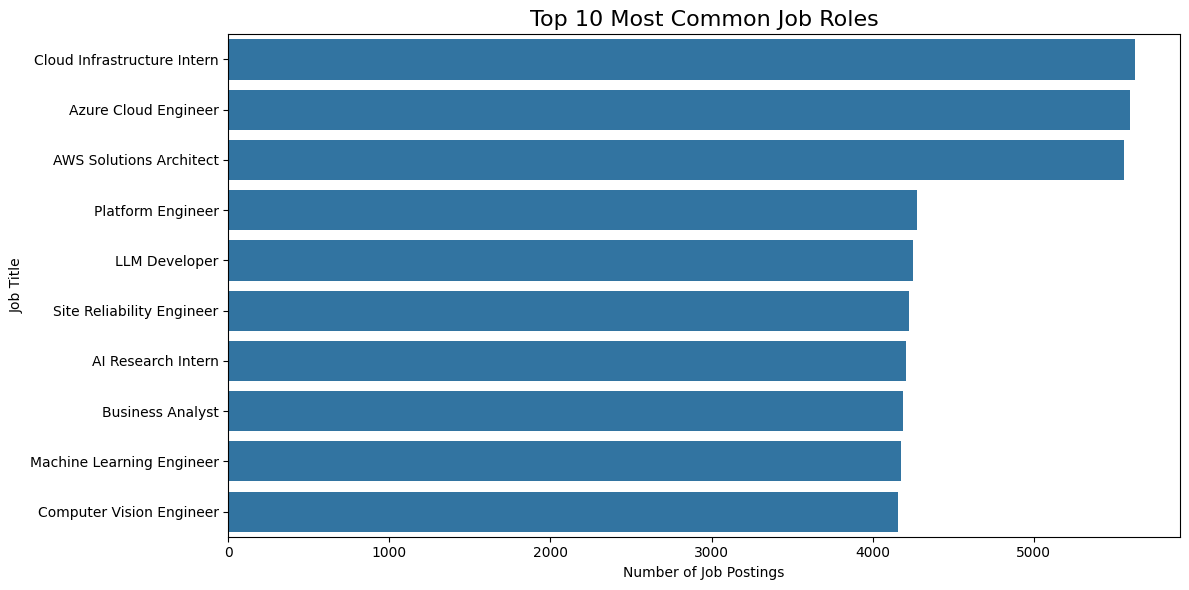

Top 10 job roles:


,job_title,count
0,Cloud Infrastructure Intern,5626
1,Azure Cloud Engineer,5596
2,AWS Solutions Architect,5560
3,Platform Engineer,4272
4,LLM Developer,4251
5,Site Reliability Engineer,4226
6,AI Research Intern,4204
7,Business Analyst,4191
8,Machine Learning Engineer,4178
9,Computer Vision Engineer,4154


In [10]:
# CareerLens: Top 10 Most Common Job Roles

top_jobs = df["job_title"].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_jobs.values, y=top_jobs.index)

plt.title("Top 10 Most Common Job Roles", fontsize=16)
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()

print("Top 10 job roles:")
display(top_jobs.reset_index())


Job description column found: True


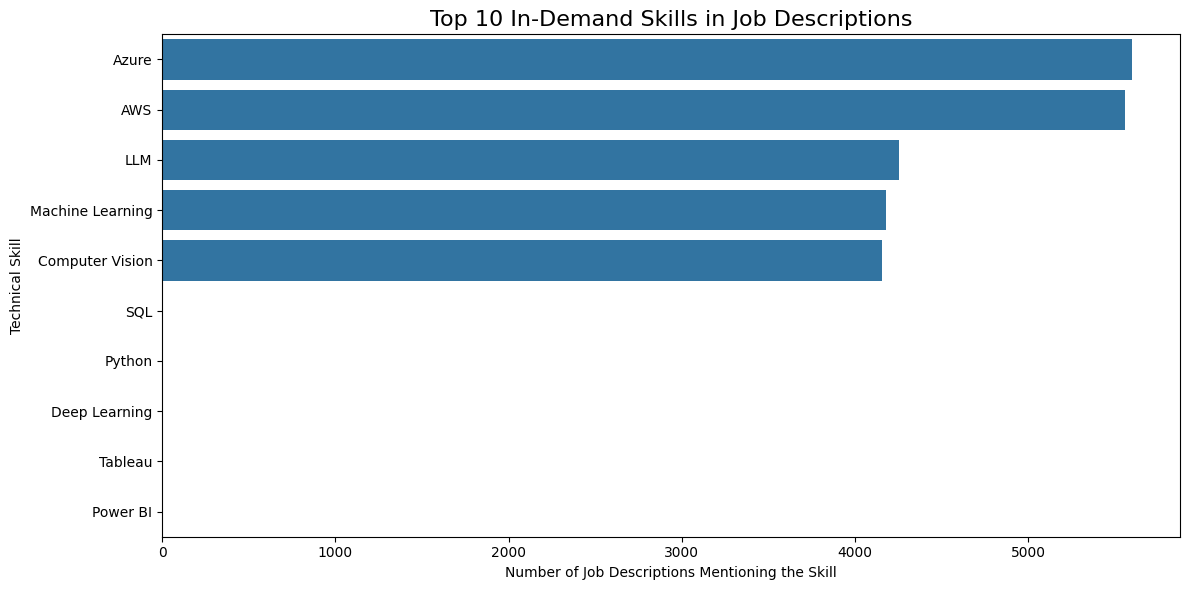

,index,0
0,Azure,5596
1,AWS,5560
2,LLM,4251
3,Machine Learning,4178
4,Computer Vision,4154
5,SQL,0
6,Python,0
7,Deep Learning,0
8,Tableau,0
9,Power BI,0


In [11]:
# CareerLens: Most In-Demand Skills

from collections import Counter
import re

# Find the job description column
print("Job description column found:", "job_description" in df.columns)

# Common technical skills to search for
skills = [
    "Python", "SQL", "Excel", "Power BI", "Tableau",
    "Machine Learning", "Deep Learning", "TensorFlow",
    "PyTorch", "AWS", "Azure", "Docker", "Kubernetes",
    "Git", "Linux", "Java", "C++", "R", "NLP",
    "Computer Vision", "LLM", "Spark", "Hadoop"
]

# Combine job descriptions into searchable text
descriptions = df["job_description"].fillna("").astype(str)

# Count descriptions that mention each skill
skill_counts = {}

for skill in skills:
    pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"
    skill_counts[skill] = descriptions.str.contains(
        pattern, case=False, regex=True
    ).sum()

# Display the top 10 skills
top_skills = pd.Series(skill_counts).sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_skills.values, y=top_skills.index)

plt.title("Top 10 In-Demand Skills in Job Descriptions", fontsize=16)
plt.xlabel("Number of Job Descriptions Mentioning the Skill")
plt.ylabel("Technical Skill")
plt.tight_layout()
plt.show()

display(top_skills.reset_index())

In [12]:
# CareerLens: Inspect actual job descriptions

for i, description in enumerate(
    df["job_description"].dropna().head(5), start=1
):
    print(f"\nJOB DESCRIPTION {i}")
    print(str(description)[:1000])
    print("-" * 60)


JOB DESCRIPTION 1
<p>We are hiring a passionate Machine Learning Engineer to join our engineering cluster. Hands-on experience with core tech workflows preferred.</p>
------------------------------------------------------------

JOB DESCRIPTION 2
<p>We are hiring a passionate Full Stack Developer to join our engineering cluster. Hands-on experience with core tech workflows preferred.</p>
------------------------------------------------------------

JOB DESCRIPTION 3
<p>We are hiring a passionate Web Development Intern to join our engineering cluster. Hands-on experience with core tech workflows preferred.</p>
------------------------------------------------------------

JOB DESCRIPTION 4
<p>We are hiring a passionate DevOps Intern to join our engineering cluster. Hands-on experience with core tech workflows preferred.</p>
------------------------------------------------------------

JOB DESCRIPTION 5
<p>We are hiring a passionate Cybersecurity Analyst to join our engineering cluster. 

In [13]:

# CareerLens: Search for skill-related columns

print("All dataset columns:\n")

for column in df.columns:
    print(column)

print("\nPossible skill-related columns:")

skill_columns = [
    column for column in df.columns
    if any(word in column.lower()
           for word in ["skill", "technology", "qualification", "requirement"])
]

print(skill_columns)


All dataset columns:

job_title
job_category
company_name
company_size
industry
company_type
location_city
location_state
location_country
work_mode
salary_minimum
salary_maximum
salary_currency
stipend_amount
experience_level
experience_required
education_required
employment_type
contract_type
skills_extracted
skill_count
job_description
posted_date
application_deadline
source_platform
applicant_count
job_benefits
technical_domain
interview_difficulty
probation_period
shift_type
is_active
career_growth_index

Possible skill-related columns:
['skills_extracted', 'skill_count']


In [14]:
# CareerLens: Inspect the extracted skills

print("Sample skills data:")
display(df[["job_title", "skills_extracted", "skill_count"]].head(10))

print("\nMissing skills records:")
print(df["skills_extracted"].isna().sum())

print("\nExample skills value:")
print(df["skills_extracted"].iloc[0])


Sample skills data:


,job_title,skills_extracted,skill_count
0,Machine Learning Engineer,"Python, PyTorch, TensorFlow, Scikit-Learn, Ope...",6
1,Full Stack Developer,"HTML, CSS, JavaScript, React, Node.js, Express...",8
2,Web Development Intern,"HTML, CSS, JavaScript, React, Node.js, Express...",8
3,DevOps Intern,"Docker, Kubernetes, Jenkins, CI/CD, Linux, Ter...",7
4,Cybersecurity Analyst,"Network Security, Wireshark, Metasploit, Linux...",6
5,Site Reliability Engineer,"Docker, Kubernetes, Jenkins, CI/CD, Linux, Ter...",7
6,Cloud Infrastructure Intern,"AWS, Azure, CloudFormation, IAM, EC2, S3, Arch...",7
7,Data Analytics Intern,"Python, SQL, Tableau, Power BI, Pandas, NumPy,...",7
8,Azure Cloud Engineer,"AWS, Azure, CloudFormation, IAM, EC2, S3, Arch...",7
9,Platform Engineer,"Docker, Kubernetes, Jenkins, CI/CD, Linux, Ter...",7



Missing skills records:
0

Example skills value:
Python, PyTorch, TensorFlow, Scikit-Learn, OpenAI API, HuggingFace


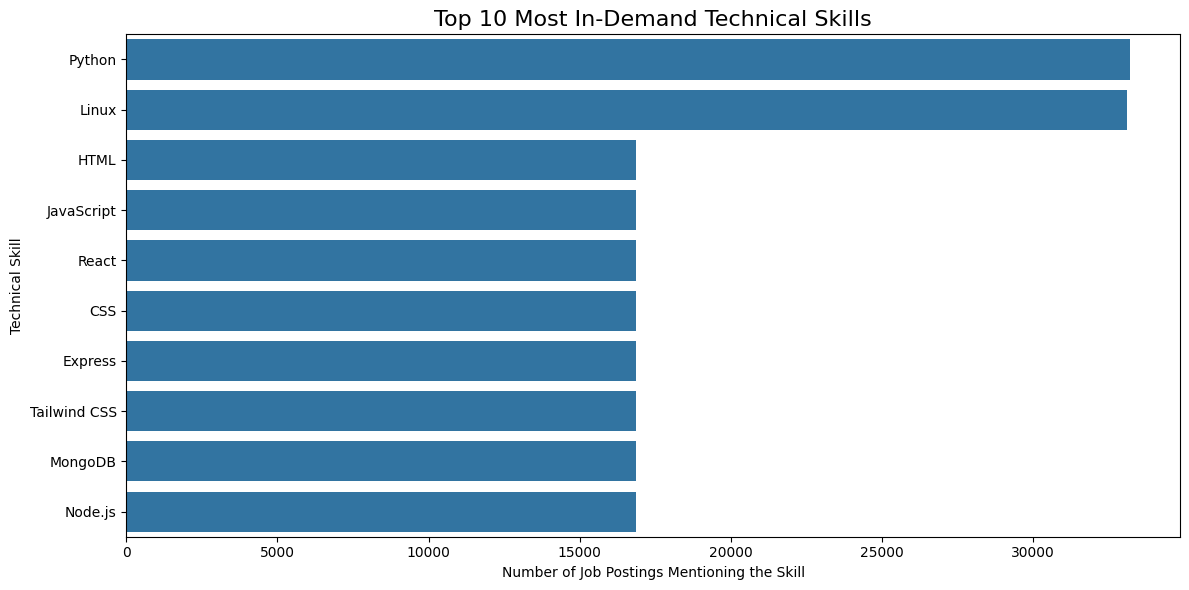

Top 10 technical skills:


,Skill,Job Postings
0,Python,33212
1,Linux,33134
2,HTML,16872
3,JavaScript,16872
4,React,16872
5,CSS,16872
6,Express,16872
7,Tailwind CSS,16872
8,MongoDB,16872
9,Node.js,16872


In [15]:

# CareerLens: Most In-Demand Technical Skills

from collections import Counter

# Split skills and count each skill
all_skills = []

for skills in df["skills_extracted"].dropna():
    skill_list = [skill.strip() for skill in str(skills).split(",")]
    all_skills.extend(skill_list)

skill_counts = Counter(all_skills)

# Get the top 10 skills
top_skills = pd.Series(skill_counts).sort_values(
    ascending=False
).head(10)

# Create a chart
plt.figure(figsize=(12, 6))
sns.barplot(x=top_skills.values, y=top_skills.index)

plt.title("Top 10 Most In-Demand Technical Skills", fontsize=16)
plt.xlabel("Number of Job Postings Mentioning the Skill")
plt.ylabel("Technical Skill")
plt.tight_layout()
plt.show()

# Display results
print("Top 10 technical skills:")
display(top_skills.rename_axis("Skill").reset_index(name="Job Postings"))


In [16]:

# CareerLens: Inspect salary information

salary_columns = [
    "job_title",
    "salary_minimum",
    "salary_maximum",
    "salary_currency"
]

display(df[salary_columns].head(10))

print("\nMissing salary values:")
display(df[["salary_minimum", "salary_maximum"]].isnull().sum())

print("\nSalary currencies:")
display(df["salary_currency"].value_counts(dropna=False))


,job_title,salary_minimum,salary_maximum,salary_currency
0,Machine Learning Engineer,303344,1696925,INR
1,Full Stack Developer,326766,1714068,INR
2,Web Development Intern,549068,1235656,INR
3,DevOps Intern,386407,1090597,INR
4,Cybersecurity Analyst,510779,1610239,INR
5,Site Reliability Engineer,305591,702450,INR
6,Cloud Infrastructure Intern,438439,1163254,INR
7,Data Analytics Intern,515917,1635217,INR
8,Azure Cloud Engineer,566008,1386951,INR
9,Platform Engineer,566498,1466436,INR



Missing salary values:


,0
salary_minimum,0
salary_maximum,0



Salary currencies:


,count
salary_currency,
INR,100000


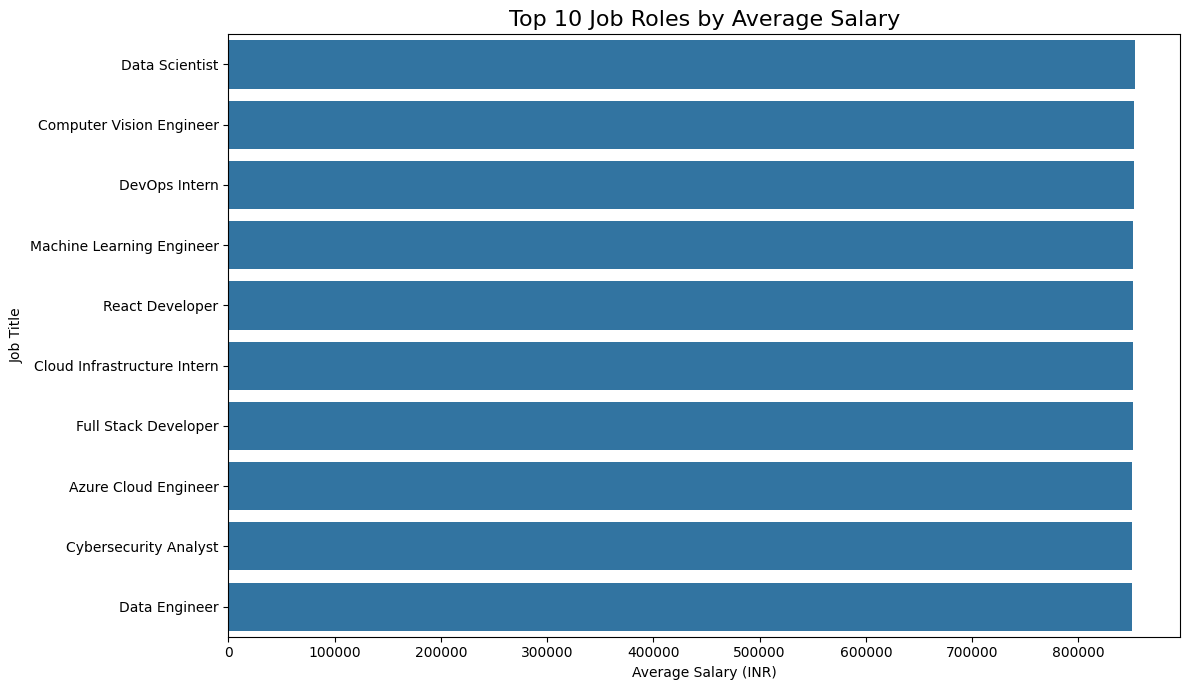

,Job Title,Average Salary (INR)
0,Data Scientist,852942
1,Computer Vision Engineer,852246
2,DevOps Intern,852225
3,Machine Learning Engineer,851623
4,React Developer,851432
5,Cloud Infrastructure Intern,851103
6,Full Stack Developer,851021
7,Azure Cloud Engineer,850806
8,Cybersecurity Analyst,850725
9,Data Engineer,849972


In [17]:

# CareerLens: Salary Analysis

# Calculate the midpoint of each salary range
df["average_salary"] = (
    df["salary_minimum"] + df["salary_maximum"]
) / 2

# Calculate average salary for each job title
salary_by_job = (
    df.groupby("job_title")["average_salary"]
    .mean()
    .sort_values(ascending=False)
)

# Select the 10 highest-paying job titles
top_salary_jobs = salary_by_job.head(10)

# Create the chart
plt.figure(figsize=(12, 7))
sns.barplot(
    x=top_salary_jobs.values,
    y=top_salary_jobs.index
)

plt.title("Top 10 Job Roles by Average Salary", fontsize=16)
plt.xlabel("Average Salary (INR)")
plt.ylabel("Job Title")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

# Display salary results
salary_results = top_salary_jobs.reset_index()
salary_results.columns = ["Job Title", "Average Salary (INR)"]
salary_results["Average Salary (INR)"] = (
    salary_results["Average Salary (INR)"].round(0).astype(int)
)

display(salary_results)


In [18]:

# CareerLens: Check salary data quality

print("1. Overall salary statistics")
display(df[["salary_minimum", "salary_maximum", "average_salary"]].describe().round(2))

print("\n2. Number of unique salary values")
print("Minimum salary values:", df["salary_minimum"].nunique())
print("Maximum salary values:", df["salary_maximum"].nunique())

print("\n3. Salary variation across job titles")

salary_check = df.groupby("job_title").agg(
    average_salary=("average_salary", "mean"),
    salary_std=("average_salary", "std"),
    minimum=("salary_minimum", "min"),
    maximum=("salary_maximum", "max"),
    records=("job_title", "size")
).sort_values("average_salary", ascending=False)

display(salary_check.head(15).round(2))

print("\n4. Salary range variation")
df["salary_range"] = df["salary_maximum"] - df["salary_minimum"]
display(df["salary_range"].describe().round(2))


1. Overall salary statistics


,salary_minimum,salary_maximum,average_salary
count,100000.00,100000.00,100000.00
mean,449925.83,1249972.79,849949.31
std,86716.47,317624.14,164654.47
min,300004.00,700013.00,501320.00
25%,374689.75,975232.75,712808.00
50%,449779.50,1250729.50,850313.75
75%,525219.50,1523974.50,987408.75
max,599999.00,1799996.00,1198997.50



2. Number of unique salary values
Minimum salary values: 85146
Maximum salary values: 95577

3. Salary variation across job titles


,average_salary,salary_std,minimum,maximum,records
job_title,,,,,
Data Scientist,852942.37,167410.73,300046,1799992,4108
Computer Vision Engineer,852245.95,164131.38,300050,1799733,4154
DevOps Intern,852225.10,163714.08,300021,1799678,4117
Machine Learning Engineer,851622.76,163626.95,300032,1799696,4178
React Developer,851432.03,165269.24,300004,1799817,3309
Cloud Infrastructure Intern,851102.84,163561.17,300059,1799676,5626
Full Stack Developer,851021.30,166034.93,300004,1799889,3352
Azure Cloud Engineer,850806.11,163668.85,300088,1799478,5596
Cybersecurity Analyst,850724.74,165130.34,300065,1799788,4040



4. Salary range variation


,salary_range
count,100000.00
mean,800046.96
std,329188.84
min,102835.00
25%,524496.00
50%,800891.00
75%,1073776.25
max,1498440.00


Experience levels:


,count
experience_level,
Mid-Senior Level,59871
Freshers / Entry Level,40129



Average salary by experience level:


,mean,median,count
experience_level,,,
Freshers / Entry Level,850379.06,851123.0,40129
Mid-Senior Level,849661.27,849819.0,59871


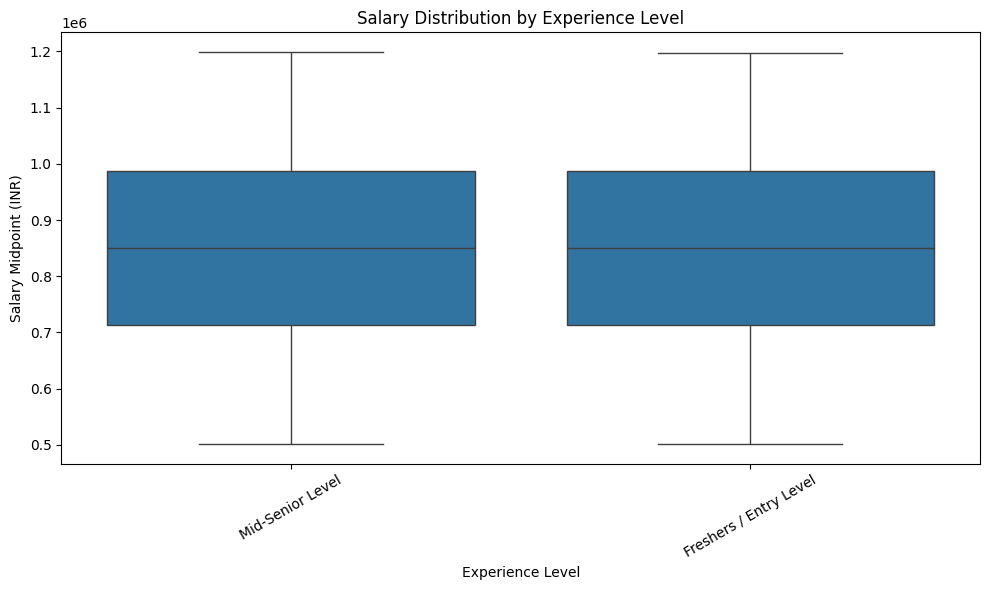

In [19]:

# CareerLens: Explore salary by experience level

print("Experience levels:")
display(df["experience_level"].value_counts(dropna=False))

print("\nAverage salary by experience level:")

experience_salary = (
    df.groupby("experience_level")["average_salary"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(experience_salary.round(2))

# Visualize salary by experience level
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="experience_level",
    y="average_salary"
)

plt.title("Salary Distribution by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Salary Midpoint (INR)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Jobs by work mode:


,count
work_mode,
Remote,40018
Hybrid,39654
On-site,20328



Average salary by work mode:


,mean,median,count
work_mode,,,
On-site,850779.31,852300.25,20328
Hybrid,849951.95,850786.50,39654
Remote,849525.09,848788.25,40018


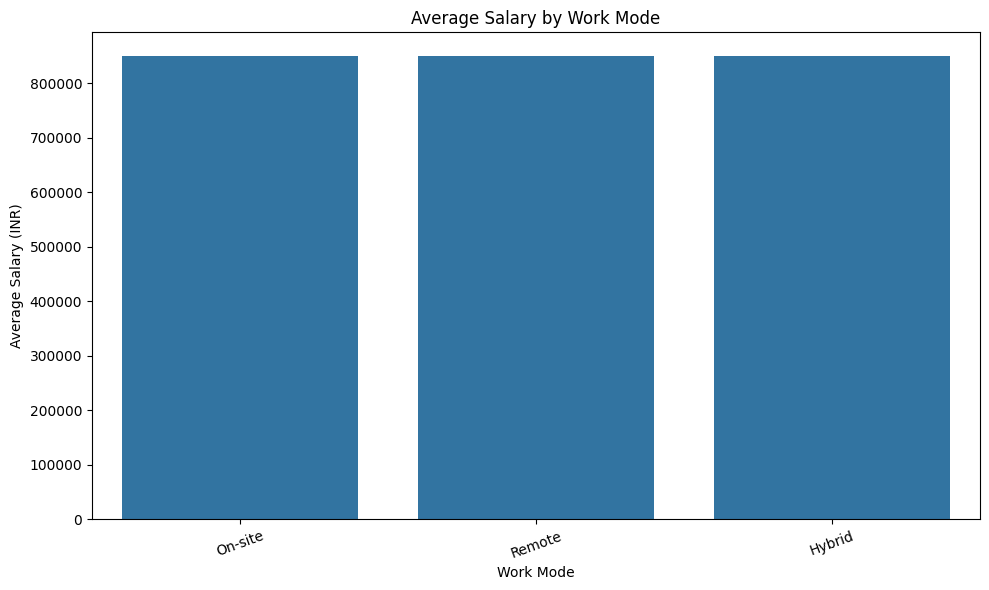

In [20]:
# CareerLens: Salary analysis by work mode

print("Jobs by work mode:")
display(df["work_mode"].value_counts(dropna=False))

print("\nAverage salary by work mode:")

work_mode_salary = (
    df.groupby("work_mode")["average_salary"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(work_mode_salary.round(2))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="work_mode",
    y="average_salary",
    errorbar=None
)

plt.title("Average Salary by Work Mode")
plt.xlabel("Work Mode")
plt.ylabel("Average Salary (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Top 10 Cities by Number of Job Postings:


,City,Number of Jobs
0,Chennai,12636
1,Noida,12622
2,Gurgaon,12521
3,Delhi NCR,12515
4,Pune,12452
5,Mumbai,12443
6,Hyderabad,12439
7,Bangalore,12372


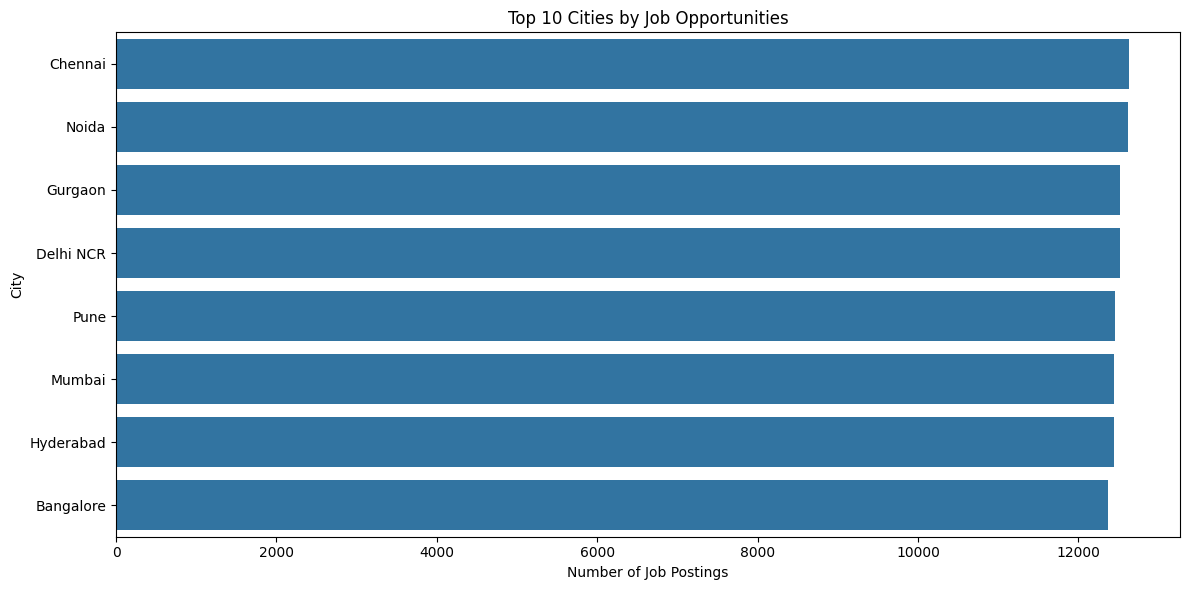

In [21]:
# CareerLens: Job opportunities by location

print("Top 10 Cities by Number of Job Postings:")

top_cities = df["location_city"].value_counts().head(10)

display(
    top_cities.reset_index().rename(
        columns={
            "location_city": "City",
            "count": "Number of Jobs"
        }
    )
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_cities.values,
    y=top_cities.index,
    errorbar=None
)

plt.title("Top 10 Cities by Job Opportunities")
plt.xlabel("Number of Job Postings")
plt.ylabel("City")
plt.tight_layout()
plt.show()

Salary Statistics by Job Category:


,mean,median,count
job_category,,,
AI / ML Engineering,850549.94,851192.50,16787
Data Science,850359.91,850949.50,16425
Cloud Architecture,850358.51,850868.75,16782
Web Development,849687.60,850282.75,16872
DevOps Core,849465.83,850447.50,16697
Cybersecurity,849267.60,847876.50,16437


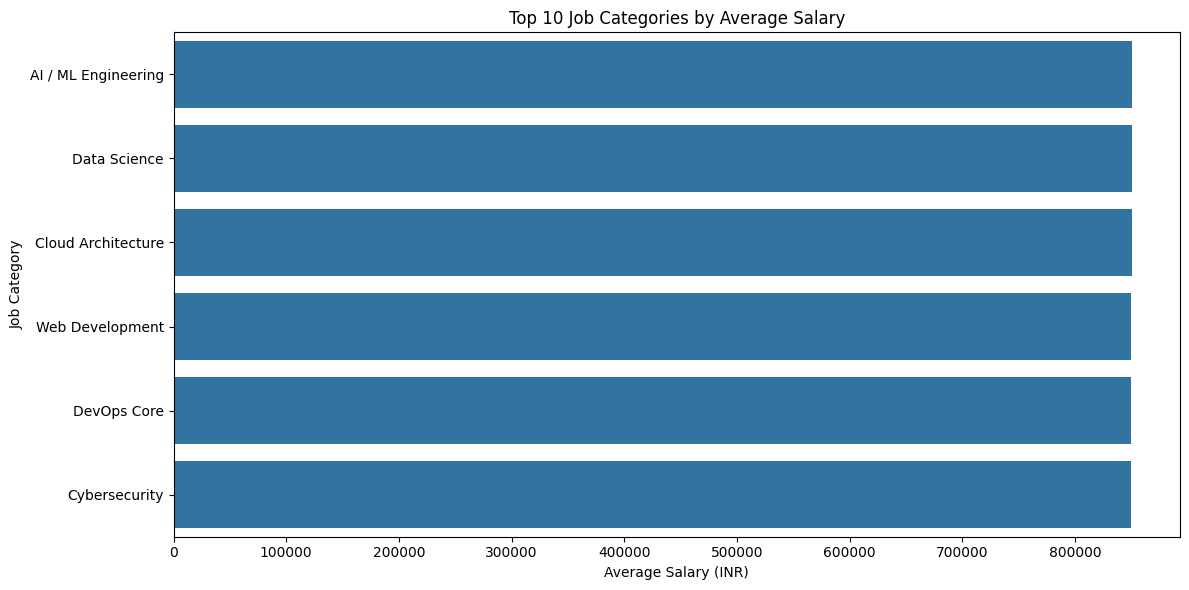

In [22]:
# CareerLens: Salary analysis by job category

category_salary = (
    df.groupby("job_category")["average_salary"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

print("Salary Statistics by Job Category:")
display(category_salary.round(2))

top_categories = category_salary.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_categories["mean"],
    y=top_categories.index,
    errorbar=None
)

plt.title("Top 10 Job Categories by Average Salary")
plt.xlabel("Average Salary (INR)")
plt.ylabel("Job Category")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

In [23]:
# CareerLens: Salary Prediction Model

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select input features
categorical_features = [
    "job_category",
    "experience_level",
    "work_mode",
    "company_size",
    "industry",
    "education_required",
    "employment_type",
    "technical_domain"
]

numerical_features = ["skill_count"]

features = categorical_features + numerical_features
target = "average_salary"

# Prepare data
X = df[features].copy()
y = df[target].copy()

# Handle missing values and encode text columns
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ),
        (
            "numerical",
            SimpleImputer(strategy="median"),
            numerical_features
        )
    ]
)

# Create the machine learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
print("Training CareerLens salary prediction model...")

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation Results")
print("------------------------")
print(f"Training records: {len(X_train):,}")
print(f"Testing records: {len(X_test):,}")
print(f"Mean Absolute Error (MAE): ₹{mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ₹{rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Training CareerLens salary prediction model...

Model Evaluation Results
------------------------
Training records: 80,000
Testing records: 20,000
Mean Absolute Error (MAE): ₹142,025.22
Root Mean Squared Error (RMSE): ₹165,777.34
R² Score: -0.0047


Model vs Baseline Comparison:


,Metric,CareerLens Model,Baseline Model
0,MAE (INR),142025.2216,141795.4500
1,RMSE (INR),165777.3379,165385.8676
2,R² Score,-0.0047,-0.0000


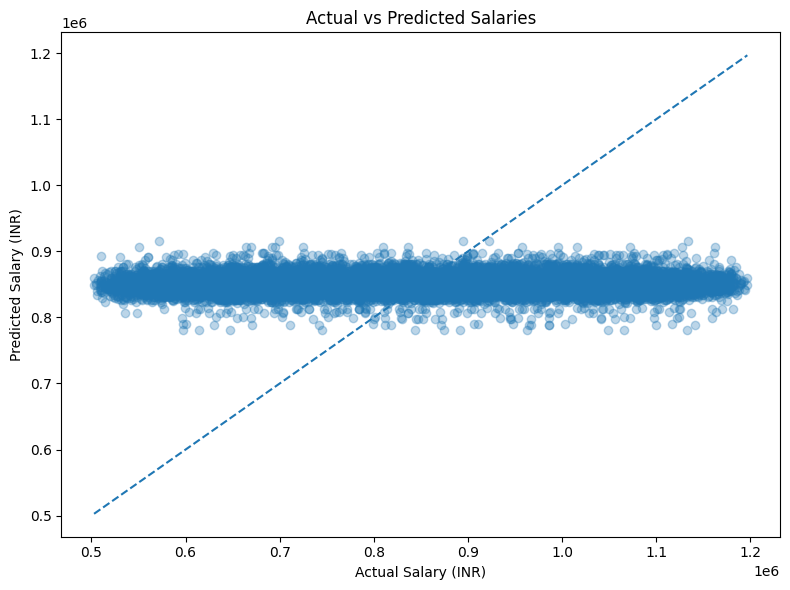

In [24]:
# CareerLens: Compare model against a simple baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline predicts the average salary from training data
baseline_pred = np.full(len(y_test), y_train.mean())

# Calculate baseline metrics
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

# Compare both models
comparison = pd.DataFrame({
    "Metric": ["MAE (INR)", "RMSE (INR)", "R² Score"],
    "CareerLens Model": [
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ],
    "Baseline Model": [
        baseline_mae,
        baseline_rmse,
        baseline_r2
    ]
})

print("Model vs Baseline Comparison:")
display(comparison.round(4))

# Plot actual versus predicted salaries
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

min_salary = min(y_test.min(), y_pred.min())
max_salary = max(y_test.max(), y_pred.max())

plt.plot(
    [min_salary, max_salary],
    [min_salary, max_salary],
    linestyle="--"
)

plt.title("Actual vs Predicted Salaries")
plt.xlabel("Actual Salary (INR)")
plt.ylabel("Predicted Salary (INR)")
plt.tight_layout()
plt.show()

1. Salary correlation with numerical features


,Correlation with Average Salary
salary_maximum,0.9647
salary_minimum,0.2640
applicant_count,0.0025
skill_count,-0.0003


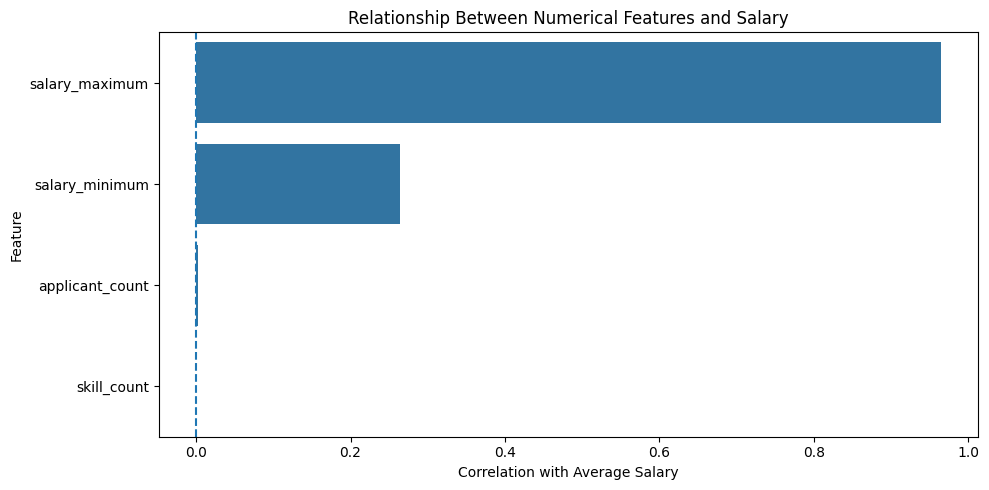


2. Average salary by technical domain


,mean,median,count
technical_domain,,,
Core Applied Machine Learning,850549.94,851192.50,16787
Analytics & Business Intelligence,850359.91,850949.50,16425
Enterprise Cloud Systems,850358.51,850868.75,16782
Frontend & Backend Engineering,849687.60,850282.75,16872
Cloud & Infrastructure Systems,849465.83,850447.50,16697
Network & Information Security,849267.60,847876.50,16437


In [25]:
# CareerLens: Check feature relationships with salary

print("1. Salary correlation with numerical features")

numeric_columns = [
    "salary_minimum",
    "salary_maximum",
    "average_salary",
    "skill_count",
    "applicant_count",
    "career_growth_index"
]

numeric_columns = [
    col for col in numeric_columns
    if col in df.columns
]

correlations = (
    df[numeric_columns]
    .corr(numeric_only=True)["average_salary"]
    .drop("average_salary")
    .sort_values(ascending=False)
)

display(correlations.to_frame("Correlation with Average Salary").round(4))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=correlations.values,
    y=correlations.index,
    errorbar=None
)

plt.title("Relationship Between Numerical Features and Salary")
plt.xlabel("Correlation with Average Salary")
plt.ylabel("Feature")
plt.axvline(0, linestyle="--")
plt.tight_layout()
plt.show()

print("\n2. Average salary by technical domain")

domain_salary = (
    df.groupby("technical_domain")["average_salary"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(domain_salary.round(2))

1. Career Growth Index Statistics


,career_growth_index
count,100000.00
mean,81.51
std,9.82
min,65.00
25%,73.00
50%,82.00
75%,90.00
max,98.00



2. Average Career Growth Index by Job Category


,mean,median,count
job_category,,,
AI / ML Engineering,81.62,82.0,16787
DevOps Core,81.55,82.0,16697
Web Development,81.50,82.0,16872
Cloud Architecture,81.50,81.0,16782
Cybersecurity,81.45,81.0,16437
Data Science,81.43,81.0,16425


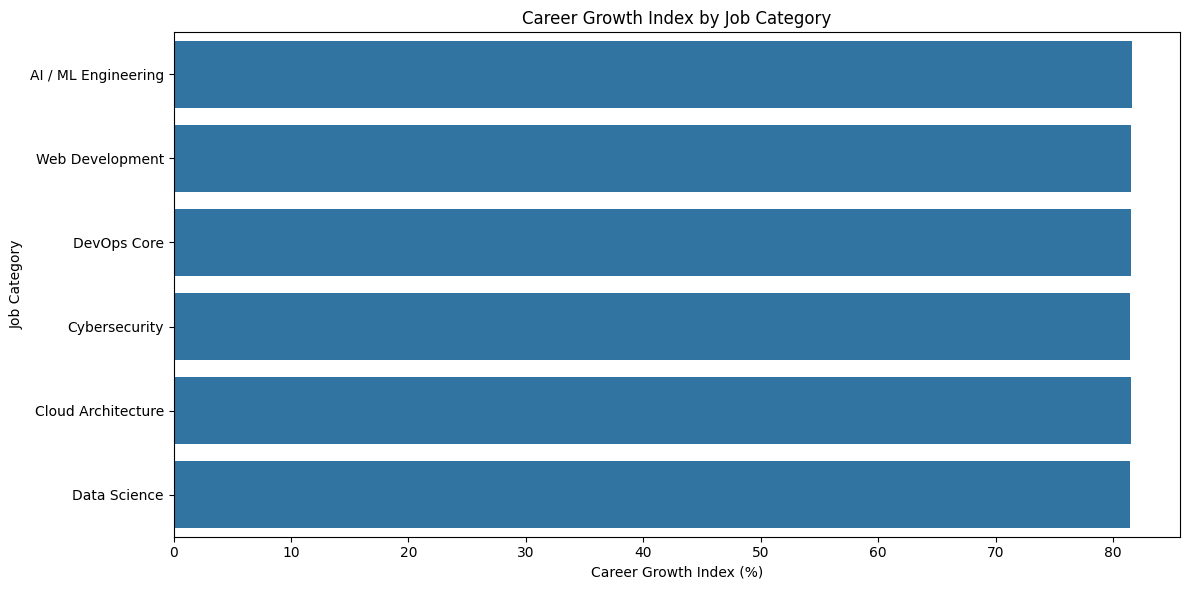


3. Top 10 Job Titles by Career Growth Index


,Average Career Growth Index (%)
job_title,
Computer Vision Engineer,81.90
Web Development Intern,81.79
Data Scientist,81.74
Site Reliability Engineer,81.71
Security Intern,81.67
Backend Developer,81.66
AI Research Intern,81.61
Azure Cloud Engineer,81.59
LLM Developer,81.54


In [26]:
# CareerLens: Career Growth Analysis (Fixed)

# Convert percentage text into numeric values
df["career_growth_index"] = pd.to_numeric(
    df["career_growth_index"]
    .astype(str)
    .str.replace("%", "", regex=False),
    errors="coerce"
)

print("1. Career Growth Index Statistics")
display(df["career_growth_index"].describe().round(2).to_frame())

print("\n2. Average Career Growth Index by Job Category")

growth_by_category = (
    df.groupby("job_category")["career_growth_index"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(growth_by_category.round(2))

# Visualize career growth by category
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="career_growth_index",
    y="job_category",
    errorbar=None
)

plt.title("Career Growth Index by Job Category")
plt.xlabel("Career Growth Index (%)")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

print("\n3. Top 10 Job Titles by Career Growth Index")

growth_by_job = (
    df.groupby("job_title")["career_growth_index"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

display(
    growth_by_job
    .round(2)
    .to_frame("Average Career Growth Index (%)")
)

In [27]:
# CareerLens: Skill-Based Job Recommendations

from collections import Counter

# Create a list of skills for each job title
job_skills = {}

for _, row in df[["job_title", "skills_extracted"]].dropna().iterrows():
    job = str(row["job_title"])
    skills = {
        skill.strip().lower()
        for skill in str(row["skills_extracted"]).split(",")
        if skill.strip()
    }

    if job not in job_skills:
        job_skills[job] = set()

    job_skills[job].update(skills)

# Enter your skills here
my_skills = [
    "Python",
    "SQL",
    "Pandas",
    "NumPy",
    "Machine Learning"
]

my_skills = {skill.strip().lower() for skill in my_skills}

# Calculate skill matches for each job
recommendations = []

for job, required_skills in job_skills.items():
    matched_skills = my_skills.intersection(required_skills)

    if required_skills:
        match_percentage = (
            len(matched_skills) / len(required_skills)
        ) * 100

        recommendations.append({
            "Job Title": job,
            "Match Percentage": round(match_percentage, 2),
            "Matched Skills": ", ".join(sorted(matched_skills)),
            "Matching Skills Count": len(matched_skills),
            "Total Listed Skills": len(required_skills)
        })

# Show the best matches first
recommendations_df = pd.DataFrame(recommendations)

recommendations_df = recommendations_df.sort_values(
    by=["Match Percentage", "Matching Skills Count"],
    ascending=False
).head(10)

print("Your Skills:")
print(", ".join(sorted(my_skills)))

print("\nTop 10 Recommended Job Roles:")
display(recommendations_df.reset_index(drop=True))

Your Skills:
machine learning, numpy, pandas, python, sql

Top 10 Recommended Job Roles:


,Job Title,Match Percentage,Matched Skills,Matching Skills Count,Total Listed Skills
0,Data Analytics Intern,57.14,"numpy, pandas, python, sql",4,7
1,Data Engineer,57.14,"numpy, pandas, python, sql",4,7
2,Data Scientist,57.14,"numpy, pandas, python, sql",4,7
3,Business Analyst,57.14,"numpy, pandas, python, sql",4,7
4,Machine Learning Engineer,16.67,python,1,6
5,AI Research Intern,16.67,python,1,6
6,Computer Vision Engineer,16.67,python,1,6
7,LLM Developer,16.67,python,1,6
8,Full Stack Developer,0.00,,0,8
9,Web Development Intern,0.00,,0,8


In [28]:
# CareerLens: Improved Skill-Based Job Recommender

# Enter your current skills here
my_skills = [
    "Python",
    "SQL",
    "Pandas",
    "NumPy",
    "Machine Learning"
]

my_skills = {skill.strip().lower() for skill in my_skills}

recommendations = []

# Compare your skills with each job's listed skills
for job, required_skills in job_skills.items():

    required_skills = {
        skill.strip().lower()
        for skill in required_skills
        if skill.strip()
    }

    if not required_skills:
        continue

    matched = my_skills.intersection(required_skills)
    missing = required_skills - my_skills

    match_percentage = (
        len(matched) / len(required_skills)
    ) * 100

    recommendations.append({
        "Job Title": job,
        "Match Percentage": round(match_percentage, 2),
        "Matched Skills": ", ".join(sorted(matched)) or "None",
        "Skills to Learn": ", ".join(sorted(missing)) or "None",
        "Matched Skill Count": len(matched)
    })

# Rank jobs by match percentage and number of matched skills
recommendations_df = pd.DataFrame(recommendations)

recommendations_df = recommendations_df.sort_values(
    by=["Match Percentage", "Matched Skill Count"],
    ascending=False
).head(10)

print("CAREERLENS: YOUR TOP JOB MATCHES")
display(recommendations_df.reset_index(drop=True))

CAREERLENS: YOUR TOP JOB MATCHES


,Job Title,Match Percentage,Matched Skills,Skills to Learn,Matched Skill Count
0,Data Analytics Intern,57.14,"numpy, pandas, python, sql","excel, power bi, tableau",4
1,Data Engineer,57.14,"numpy, pandas, python, sql","excel, power bi, tableau",4
2,Data Scientist,57.14,"numpy, pandas, python, sql","excel, power bi, tableau",4
3,Business Analyst,57.14,"numpy, pandas, python, sql","excel, power bi, tableau",4
4,Machine Learning Engineer,16.67,python,"huggingface, openai api, pytorch, scikit-learn...",1
5,AI Research Intern,16.67,python,"huggingface, openai api, pytorch, scikit-learn...",1
6,Computer Vision Engineer,16.67,python,"huggingface, openai api, pytorch, scikit-learn...",1
7,LLM Developer,16.67,python,"huggingface, openai api, pytorch, scikit-learn...",1
8,Full Stack Developer,0.00,None,"css, express, html, javascript, mongodb, node....",0
9,Web Development Intern,0.00,None,"css, express, html, javascript, mongodb, node....",0


In [29]:
# CareerLens: Interactive Job Recommendation App

!pip -q install gradio

import pandas as pd
import gradio as gr

# Prepare job skills from the dataset
job_skills = {}

for _, row in df[["job_title", "skills_extracted"]].dropna().iterrows():
    job = str(row["job_title"])

    skills = {
        skill.strip().lower()
        for skill in str(row["skills_extracted"]).split(",")
        if skill.strip()
    }

    if job not in job_skills:
        job_skills[job] = set()

    job_skills[job].update(skills)


# Recommendation function
def recommend_jobs(user_skills):
    if not user_skills or not user_skills.strip():
        return pd.DataFrame(
            columns=[
                "Job Title",
                "Match (%)",
                "Skills You Have",
                "Skills to Learn"
            ]
        )

    my_skills = {
        skill.strip().lower()
        for skill in user_skills.split(",")
        if skill.strip()
    }

    results = []

    for job, required_skills in job_skills.items():
        if not required_skills:
            continue

        matched = my_skills.intersection(required_skills)
        missing = required_skills - my_skills

        match_percentage = len(matched) / len(required_skills) * 100

        results.append({
            "Job Title": job,
            "Match (%)": round(match_percentage, 2),
            "Skills You Have": ", ".join(sorted(matched)) or "None",
            "Skills to Learn": ", ".join(sorted(missing)) or "None",
            "Matched Count": len(matched)
        })

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by=["Match (%)", "Matched Count"],
        ascending=False
    ).head(10)

    return results_df.drop(columns=["Matched Count"]).reset_index(drop=True)


# Build the interface
with gr.Blocks(theme=gr.themes.Soft()) as app:
    gr.Markdown("# CareerLens")
    gr.Markdown(
        "### AI-Powered Career Insights and Job Recommendations\n"
        "Enter your skills, separated by commas, to explore matching jobs."
    )

    skills_input = gr.Textbox(
        label="Your Skills",
        placeholder="Python, SQL, Pandas, NumPy, Machine Learning",
        lines=3
    )

    recommend_button = gr.Button("Find My Job Matches", variant="primary")

    results_output = gr.Dataframe(
        label="Your Top 10 Job Recommendations",
        interactive=False
    )

    recommend_button.click(
        fn=recommend_jobs,
        inputs=skills_input,
        outputs=results_output
    )

app.launch(share=True)

/tmp/ipykernel_2561/3859647359.py:74: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://572a385e410eefe235.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


CAREERLENS: CAREER INSIGHTS

1. Dataset Overview
Total job postings: 100,000
Unique job titles: 24
Job categories: 6
Cities represented: 8

2. Top 5 Job Categories by Average Salary


,job_category,Average Salary (INR)
0,AI / ML Engineering,850550.0
1,Data Science,850360.0
2,Cloud Architecture,850359.0
3,Web Development,849688.0
4,DevOps Core,849466.0



3. Top 5 Most Common Job Roles


,Job Title,Number of Postings
0,Cloud Infrastructure Intern,5626
1,Azure Cloud Engineer,5596
2,AWS Solutions Architect,5560
3,Platform Engineer,4272
4,LLM Developer,4251



4. Job Distribution by Work Mode


,Work Mode,Number of Postings
0,Remote,40018
1,Hybrid,39654
2,On-site,20328


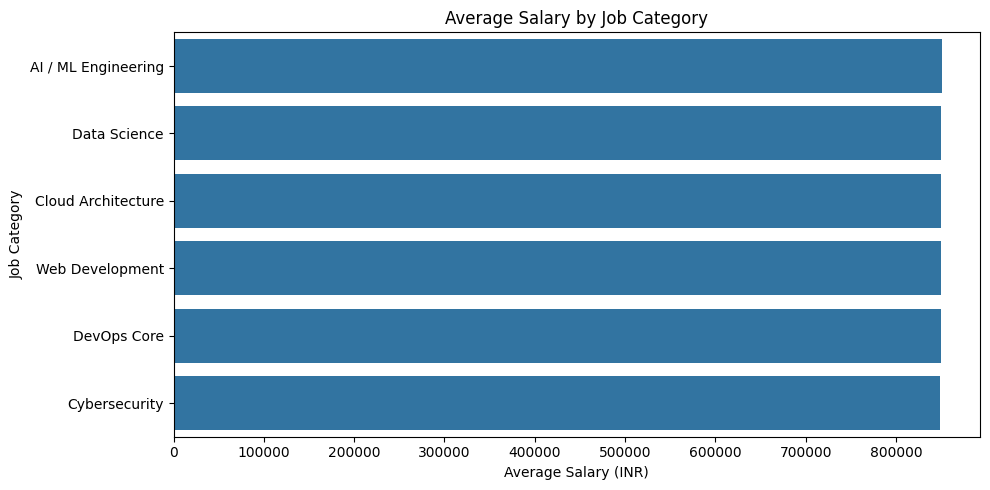

In [30]:
# CareerLens: Career Insights Dashboard

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Average salary by job category
category_salary = (
    df.groupby("job_category")["average_salary"]
    .mean()
    .sort_values(ascending=False)
)

print("CAREERLENS: CAREER INSIGHTS")
print("=" * 40)

print("\n1. Dataset Overview")
print(f"Total job postings: {len(df):,}")
print(f"Unique job titles: {df['job_title'].nunique():,}")
print(f"Job categories: {df['job_category'].nunique():,}")
print(f"Cities represented: {df['location_city'].nunique():,}")

print("\n2. Top 5 Job Categories by Average Salary")
display(
    category_salary.head(5)
    .round(0)
    .rename("Average Salary (INR)")
    .reset_index()
)

print("\n3. Top 5 Most Common Job Roles")
display(
    df["job_title"]
    .value_counts()
    .head(5)
    .rename_axis("Job Title")
    .reset_index(name="Number of Postings")
)

print("\n4. Job Distribution by Work Mode")
display(
    df["work_mode"]
    .value_counts()
    .rename_axis("Work Mode")
    .reset_index(name="Number of Postings")
)

# 5. Visualize average salary by job category
plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_salary.values,
    y=category_salary.index,
    errorbar=None
)

plt.title("Average Salary by Job Category")
plt.xlabel("Average Salary (INR)")
plt.ylabel("Job Category")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

In [31]:
# CareerLens: Career Insights Dashboard + Job Recommender

import pandas as pd
import gradio as gr

# Prepare job skills
job_skills = {}

for _, row in df[["job_title", "skills_extracted"]].dropna().iterrows():
    job = str(row["job_title"])

    skills = {
        skill.strip().lower()
        for skill in str(row["skills_extracted"]).split(",")
        if skill.strip()
    }

    if job not in job_skills:
        job_skills[job] = set()

    job_skills[job].update(skills)


# Job recommendation function
def recommend_jobs(user_skills):
    columns = [
        "Job Title",
        "Match (%)",
        "Skills You Have",
        "Skills to Learn"
    ]

    if not user_skills or not user_skills.strip():
        return pd.DataFrame(columns=columns)

    my_skills = {
        skill.strip().lower()
        for skill in user_skills.split(",")
        if skill.strip()
    }

    results = []

    for job, required_skills in job_skills.items():
        if not required_skills:
            continue

        matched = my_skills.intersection(required_skills)
        missing = required_skills - my_skills

        results.append({
            "Job Title": job,
            "Match (%)": round(
                len(matched) / len(required_skills) * 100, 2
            ),
            "Skills You Have": ", ".join(sorted(matched)) or "None",
            "Skills to Learn": ", ".join(sorted(missing)) or "None",
            "Matched Count": len(matched)
        })

    result_df = pd.DataFrame(results)

    return (
        result_df.sort_values(
            ["Match (%)", "Matched Count"],
            ascending=False
        )
        .head(10)
        .drop(columns=["Matched Count"])
        .reset_index(drop=True)
    )


# Prepare dashboard tables
top_jobs = (
    df["job_title"]
    .value_counts()
    .head(10)
    .rename_axis("Job Title")
    .reset_index(name="Job Postings")
)

category_salary = (
    df.groupby("job_category")["average_salary"]
    .mean()
    .sort_values(ascending=False)
    .round(0)
    .rename("Average Salary (INR)")
    .reset_index()
)

work_modes = (
    df["work_mode"]
    .value_counts()
    .rename_axis("Work Mode")
    .reset_index(name="Job Postings")
)


# Build the app
with gr.Blocks() as app:

    gr.Markdown("""
    # CareerLens
    ### Explore Jobs. Discover Skills. Plan Your Career.

    Find job matches based on your skills and explore career insights
    from the available job-posting dataset.
    """)

    with gr.Row():
        gr.Markdown(f"""
        ### Job Postings
        # {len(df):,}
        """)

        gr.Markdown(f"""
        ### Job Titles
        # {df["job_title"].nunique():,}
        """)

        gr.Markdown(f"""
        ### Job Categories
        # {df["job_category"].nunique():,}
        """)

        gr.Markdown(f"""
        ### Cities
        # {df["location_city"].nunique():,}
        """)

    gr.Markdown("---")
    gr.Markdown("## Find Your Job Matches")

    skills_input = gr.Textbox(
        label="Enter your skills",
        placeholder="Python, SQL, Pandas, NumPy, Machine Learning",
        lines=2
    )

    recommend_button = gr.Button(
        "Find My Job Matches",
        variant="primary"
    )

    results_output = gr.Dataframe(
        headers=[
            "Job Title",
            "Match (%)",
            "Skills You Have",
            "Skills to Learn"
        ],
        label="Top 10 Recommended Jobs",
        interactive=False
    )

    recommend_button.click(
        fn=recommend_jobs,
        inputs=skills_input,
        outputs=results_output
    )

    gr.Markdown("---")
    gr.Markdown("## Career Insights")

    with gr.Tab("Popular Job Roles"):
        gr.Dataframe(
            value=top_jobs,
            label="Most Common Job Titles",
            interactive=False
        )

    with gr.Tab("Salary by Category"):
        gr.Dataframe(
            value=category_salary,
            label="Average Salary by Job Category",
            interactive=False
        )
        gr.Markdown(
            "Note: Salaries are dataset estimates, not verified job offers."
        )

    with gr.Tab("Work Modes"):
        gr.Dataframe(
            value=work_modes,
            label="Job Postings by Work Mode",
            interactive=False
        )

    gr.Markdown("""
    ---
    *CareerLens is an educational career exploration tool.
    Recommendations are based on listed skills and do not guarantee job suitability.
    Dataset figures may not represent the real job market.
    """)

app.launch(share=True, theme=gr.themes.Soft())

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c7748c640a4439ea2c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [32]:
# Step 31: CareerLens Project Summary

import pandas as pd
from IPython.display import display, Markdown

display(Markdown("""
# CareerLens — AI-Powered Career Exploration

### Project Overview
CareerLens helps users explore job opportunities based on their skills.
It also displays job trends, salary estimates, and work-mode insights.

### Key Features
- Skill-based job recommendations
- Missing-skill identification
- Job market insights
- Salary comparisons across job categories
- Work-mode distribution analysis

### Technologies Used
Python | Pandas | NumPy | Scikit-learn | Matplotlib | Gradio

### Important Limitations
- Recommendations use skill overlap, not a trained recommendation model.
- Salary figures are estimates from the available dataset.
- Dataset salary patterns may not reflect actual market salaries.
- Job matches do not guarantee employment or job suitability.

### Future Improvements
- Use verified job and salary data.
- Add skill-learning roadmaps.
- Improve recommendations with better matching methods.
- Deploy the app online for easier access.
"""))

print("CareerLens project summary created successfully!")


# CareerLens — AI-Powered Career Exploration

### Project Overview
CareerLens helps users explore job opportunities based on their skills.
It also displays job trends, salary estimates, and work-mode insights.

### Key Features
- Skill-based job recommendations
- Missing-skill identification
- Job market insights
- Salary comparisons across job categories
- Work-mode distribution analysis

### Technologies Used
Python | Pandas | NumPy | Scikit-learn | Matplotlib | Gradio

### Important Limitations
- Recommendations use skill overlap, not a trained recommendation model.
- Salary figures are estimates from the available dataset.
- Dataset salary patterns may not reflect actual market salaries.
- Job matches do not guarantee employment or job suitability.

### Future Improvements
- Use verified job and salary data.
- Add skill-learning roadmaps.
- Improve recommendations with better matching methods.
- Deploy the app online for easier access.


CareerLens project summary created successfully!


In [33]:

# Step 32: Test CareerLens Job Recommendations

test_cases = {
    "Python and Data Science": "Python, SQL, Pandas, NumPy, Machine Learning",
    "Web Development": "HTML, CSS, JavaScript, React, Node.js",
    "Cloud and DevOps": "AWS, Linux, Docker, Kubernetes, Python"
}

for test_name, skills in test_cases.items():
    print("\n" + "=" * 60)
    print("TEST:", test_name)
    print("INPUT SKILLS:", skills)
    print("=" * 60)

    results = recommend_jobs(skills)

    if results.empty:
        print("No recommendations found.")
    else:
        display(results.head(5))



TEST: Python and Data Science
INPUT SKILLS: Python, SQL, Pandas, NumPy, Machine Learning


,Job Title,Match (%),Skills You Have,Skills to Learn
0,Data Analytics Intern,57.14,"numpy, pandas, python, sql","excel, power bi, tableau"
1,Data Engineer,57.14,"numpy, pandas, python, sql","excel, power bi, tableau"
2,Data Scientist,57.14,"numpy, pandas, python, sql","excel, power bi, tableau"
3,Business Analyst,57.14,"numpy, pandas, python, sql","excel, power bi, tableau"
4,Machine Learning Engineer,16.67,python,"huggingface, openai api, pytorch, scikit-learn..."



TEST: Web Development
INPUT SKILLS: HTML, CSS, JavaScript, React, Node.js


,Job Title,Match (%),Skills You Have,Skills to Learn
0,Full Stack Developer,62.5,"css, html, javascript, node.js, react","express, mongodb, tailwind css"
1,Web Development Intern,62.5,"css, html, javascript, node.js, react","express, mongodb, tailwind css"
2,React Developer,62.5,"css, html, javascript, node.js, react","express, mongodb, tailwind css"
3,Frontend Engineer,62.5,"css, html, javascript, node.js, react","express, mongodb, tailwind css"
4,Backend Developer,62.5,"css, html, javascript, node.js, react","express, mongodb, tailwind css"



TEST: Cloud and DevOps
INPUT SKILLS: AWS, Linux, Docker, Kubernetes, Python


,Job Title,Match (%),Skills You Have,Skills to Learn
0,DevOps Intern,42.86,"docker, kubernetes, linux","ci/cd, git, jenkins, terraform"
1,Site Reliability Engineer,42.86,"docker, kubernetes, linux","ci/cd, git, jenkins, terraform"
2,Platform Engineer,42.86,"docker, kubernetes, linux","ci/cd, git, jenkins, terraform"
3,Cloud DevOps Engineer,42.86,"docker, kubernetes, linux","ci/cd, git, jenkins, terraform"
4,Machine Learning Engineer,16.67,python,"huggingface, openai api, pytorch, scikit-learn..."


In [34]:

# Step 33: Compare Salary Model Against a Simple Baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predictions from the trained model
model_predictions = model.predict(X_test)

# Simple baseline: predict the average training salary for every job
baseline_predictions = np.full(
    len(y_test),
    y_train.mean()
)

# Compare performance
evaluation = pd.DataFrame({
    "Metric": ["MAE (INR)", "RMSE (INR)", "R² Score"],
    "CareerLens Model": [
        mean_absolute_error(y_test, model_predictions),
        np.sqrt(mean_squared_error(y_test, model_predictions)),
        r2_score(y_test, model_predictions)
    ],
    "Average Salary Baseline": [
        mean_absolute_error(y_test, baseline_predictions),
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        r2_score(y_test, baseline_predictions)
    ]
})

display(evaluation.round(3))

print("\nInterpretation:")
print("Lower MAE and RMSE are better.")
print("A higher R² score is better.")
print("If the model does not beat the baseline, it needs improvement.")


,Metric,CareerLens Model,Average Salary Baseline
0,MAE (INR),142025.222,141795.450
1,RMSE (INR),165777.338,165385.868
2,R² Score,-0.005,-0.000



Interpretation:
Lower MAE and RMSE are better.
A higher R² score is better.
If the model does not beat the baseline, it needs improvement.


In [35]:

# Step 34: Check Salary Data Quality

import pandas as pd
import numpy as np

salary = pd.to_numeric(df["average_salary"], errors="coerce").dropna()

print("SALARY DATA QUALITY CHECK")
print("-" * 40)

print(f"Number of salary records: {len(salary):,}")
print(f"Minimum salary: ₹{salary.min():,.0f}")
print(f"Maximum salary: ₹{salary.max():,.0f}")
print(f"Average salary: ₹{salary.mean():,.0f}")
print(f"Median salary: ₹{salary.median():,.0f}")
print(f"Standard deviation: ₹{salary.std():,.0f}")
print(f"Unique salary values: {salary.nunique():,}")

print("\nSalary percentiles:")
display(
    salary.quantile([0, 0.25, 0.50, 0.75, 1.0])
    .rename("Salary (INR)")
    .to_frame()
    .round(0)
)

print("\nSalary data quality check completed.")


SALARY DATA QUALITY CHECK
----------------------------------------
Number of salary records: 100,000
Minimum salary: ₹501,320
Maximum salary: ₹1,198,998
Average salary: ₹849,949
Median salary: ₹850,314
Standard deviation: ₹164,654
Unique salary values: 95,895

Salary percentiles:


,Salary (INR)
0.00,501320.0
0.25,712808.0
0.50,850314.0
0.75,987409.0
1.00,1198998.0



Salary data quality check completed.


In [36]:

# Step 35: Explore Salary Differences Across Job Features

features_to_check = [
    "job_category",
    "experience_level",
    "work_mode",
    "company_size",
    "industry"
]

for feature in features_to_check:
    if feature in df.columns:
        summary = df.groupby(feature)["average_salary"].agg(
            ["count", "mean", "median", "std"]
        )

        summary = summary.sort_values(
            by="mean", ascending=False
        ).round(0)

        print("\n" + "=" * 50)
        print("SALARY ANALYSIS BY:", feature.upper())
        print("=" * 50)

        display(summary)

print("\nFeature-wise salary analysis completed!")



SALARY ANALYSIS BY: JOB_CATEGORY


,count,mean,median,std
job_category,,,,
AI / ML Engineering,16787,850550.0,851192.0,163620.0
Data Science,16425,850360.0,850950.0,165574.0
Cloud Architecture,16782,850359.0,850869.0,164171.0
Web Development,16872,849688.0,850283.0,164941.0
DevOps Core,16697,849466.0,850448.0,164339.0
Cybersecurity,16437,849268.0,847876.0,165324.0



SALARY ANALYSIS BY: EXPERIENCE_LEVEL


,count,mean,median,std
experience_level,,,,
Freshers / Entry Level,40129,850379.0,851123.0,164576.0
Mid-Senior Level,59871,849661.0,849819.0,164708.0



SALARY ANALYSIS BY: WORK_MODE


...


SALARY ANALYSIS BY: COMPANY_SIZE


,count,mean,median,std
company_size,,,,
100-500 employees,8396,852966.0,853981.0,163679.0
"500-1,000 employees",8212,851892.0,853397.0,164361.0
"1,000-5,000 employees",33254,849456.0,849955.0,164897.0
"10,000+ employees",50138,849453.0,849296.0,164702.0



SALARY ANALYSIS BY: INDUSTRY


,count,mean,median,std
industry,,,,
Information Technology,100000,849949.0,850314.0,164654.0



Feature-wise salary analysis completed!


In [37]:
# Step 36: Measure Salary Variation Between Job Categories

overall_std = df["average_salary"].std()

category_means = df.groupby("job_category")["average_salary"].mean()

variation_between_categories = category_means.std()

print("Overall salary standard deviation: ₹{:,.2f}".format(overall_std))
print("Standard deviation of category averages: ₹{:,.2f}".format(
    variation_between_categories
))

print("\nCategory averages:")
display(category_means.sort_values(ascending=False).round(2).to_frame(
    name="Average Salary (INR)"
))

print("\nInterpretation:")
if variation_between_categories < overall_std * 0.10:
    print("Category averages vary little compared with individual salary values.")
    print("Job category alone is unlikely to be a strong salary predictor.")
else:
    print("Category averages show some variation. Further analysis is useful.")


Overall salary standard deviation: ₹164,654.47
Standard deviation of category averages: ₹541.07

Category averages:


,Average Salary (INR)
job_category,
AI / ML Engineering,850549.94
Data Science,850359.91
Cloud Architecture,850358.51
Web Development,849687.60
DevOps Core,849465.83
Cybersecurity,849267.60



Interpretation:
Category averages vary little compared with individual salary values.
Job category alone is unlikely to be a strong salary predictor.


In [38]:

# Step 37: Final Job Recommendation Tests

test_cases = [
    ("Python, SQL, Pandas", "Python and Data"),
    ("HTML, CSS, JavaScript, React", "Web Development"),
    ("AWS, Linux, Docker", "Cloud and DevOps"),
    ("", "Empty Input")
]

for skills, test_name in test_cases:
    print("\n" + "=" * 45)
    print("TEST:", test_name)
    print("=" * 45)

    try:
        results = recommend_jobs(skills)

        if results.empty:
            print("No recommendations returned.")
        else:
            print("Test passed: Recommendations returned.")
            display(results.head(3))

    except Exception as error:
        print("Test failed:", error)

print("\nFinal recommendation tests completed.")



TEST: Python and Data
Test passed: Recommendations returned.


,Job Title,Match (%),Skills You Have,Skills to Learn
0,Data Analytics Intern,42.86,"pandas, python, sql","excel, numpy, power bi, tableau"
1,Data Engineer,42.86,"pandas, python, sql","excel, numpy, power bi, tableau"
2,Data Scientist,42.86,"pandas, python, sql","excel, numpy, power bi, tableau"



TEST: Web Development
Test passed: Recommendations returned.


,Job Title,Match (%),Skills You Have,Skills to Learn
0,Full Stack Developer,50.0,"css, html, javascript, react","express, mongodb, node.js, tailwind css"
1,Web Development Intern,50.0,"css, html, javascript, react","express, mongodb, node.js, tailwind css"
2,React Developer,50.0,"css, html, javascript, react","express, mongodb, node.js, tailwind css"



TEST: Cloud and DevOps
Test passed: Recommendations returned.


,Job Title,Match (%),Skills You Have,Skills to Learn
0,DevOps Intern,28.57,"docker, linux","ci/cd, git, jenkins, kubernetes, terraform"
1,Site Reliability Engineer,28.57,"docker, linux","ci/cd, git, jenkins, kubernetes, terraform"
2,Platform Engineer,28.57,"docker, linux","ci/cd, git, jenkins, kubernetes, terraform"



TEST: Empty Input
No recommendations returned.

Final recommendation tests completed.


In [40]:

# Step 38: Create a Professional README for CareerLens

readme_content = r"""# CareerLens — AI-Powered Career Exploration

CareerLens is a Python-based career exploration tool that helps users
discover job matches based on their skills and explore job-market insights.

## Features

- Skill-based job recommendations
- Identification of matching and missing skills
- Job posting insights by job title
- Salary comparisons across job categories
- Work-mode distribution analysis
- Interactive web dashboard built with Gradio

## Technologies Used

- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib and Seaborn
- Gradio
- Google Colab

## How It Works

1. Loads and explores a job-posting dataset.
2. Analyzes job roles, skills, salaries, and work modes.
3. Compares user skills with the skills listed for each job.
4. Ranks job titles using skill overlap.
5. Displays career insights in an interactive dashboard.

## Machine Learning

A Random Forest regression model was tested for salary prediction.
Its performance did not beat a simple average-salary baseline.
Therefore, its predictions should not be treated as reliable salary estimates.

## Dataset Limitations

- Salary patterns may not reflect the real job market.
- Recommendations depend on skills listed in the dataset.
- Skill-match percentages do not measure the chance of getting hired.
- Results should be used for learning and exploration only.

## Run the Project

1. Open the CareerLens notebook in Google Colab.
2. Run the notebook cells in order.
3. Run the Gradio app cell to launch the dashboard.
4. Open the generated public URL to use the app.

## Future Improvements

- Use verified job-market and salary data.
- Improve job matching and recommendation methods.
- Add career learning roadmaps.
- Deploy the app on a hosting platform.

## Author

Developed as a portfolio project to explore Python, data analysis,
machine learning evaluation, and interactive application development.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

from google.colab import files
files.download("README.md")


README.md created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>